# Exercise 6.3 · Wine quality with Keras

## Data and model
The UCI white wine dataset contains 4,898 wines with 11 measured features and a numeric quality score. The supplied notebook shuffles the rows with seed 1234, uses 3,000 wines for fitting, and monitors the remaining 1,898. Features are normalized using the fitting data. The network uses ReLU hidden units, a scalar linear output, and mean squared error. [UCI Wine Quality dataset](https://archive.ics.uci.edu/dataset/186/wine+quality).

## Recorded results

| Optimizer | Hidden widths | Batch | Epochs | Pearson r |
| --- | --- | --- | --- | --- |
| SGD, rate 0.01 | 64, 32, 16 | 32 | 300 | ≈0.59 |
| SGD + 0.9 momentum, rate 0.01 | 64, 32, 16 | 32 | 300 | 0.576 |
| Adam, rate 0.001 | 64, 32, 16 | 32 | 300 | ≈0.55 |
| Adam, rate 0.001 | 20 | 5 | 30 | 0.583 |
| Adam, rate 0.001 | 64, 32, 16 | 5 | 30 | 0.602 |

The deepest Adam run with batches of five gave the largest recorded correlation. Its final training MSE was 0.3854 and the monitored MSE was 0.5755. The single layer run had lower and steadier monitored loss near the end, despite its lower correlation. Correlation reflects whether high predictions tend to accompany high ratings. MSE also depends on the absolute size of the errors.

The 300 epoch runs show training loss continuing to fall after the monitored loss begins to rise. Momentum brought SGD to its low loss region earlier in the recorded deep runs. Momentum carries part of the previous update forward, while Adam scales its updates by estimates of the first and second gradient moments. The two recorded Adam runs with 30 and 300 epochs also used different batch sizes, so their difference cannot identify the effect of batch size alone.

The original run monitored the same 1,898 wines used to compute the reported correlations. Those scores describe the recorded comparison. The corrected experiment below sets aside a separate validation split, uses a fixed training schedule, and compares batches of one and five with the same architecture and optimizer. The corrected configuration has no saved training results in this export.

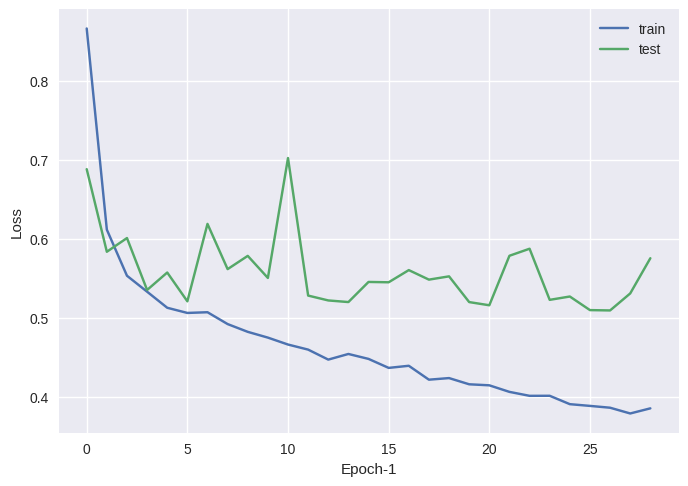

Figure 1. Recorded loss for Adam, widths 64, 32, 16, batch size five. The original plot omits epoch 1 and labels the monitored split “test.”

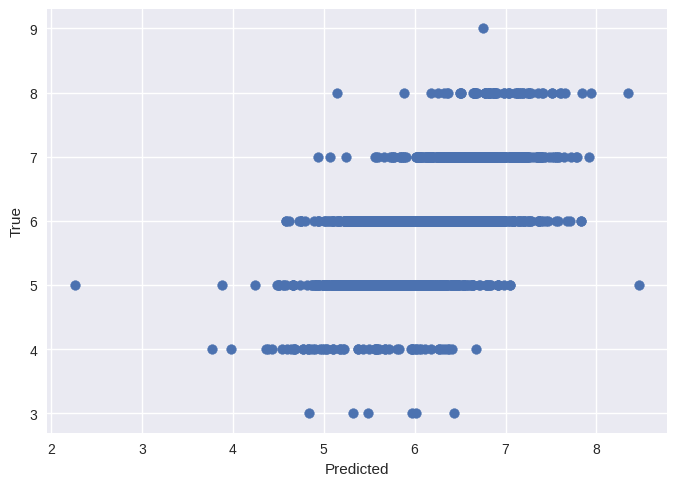

Figure 2. Recorded predictions versus observed scores for the same model. Pearson r = 0.6020.

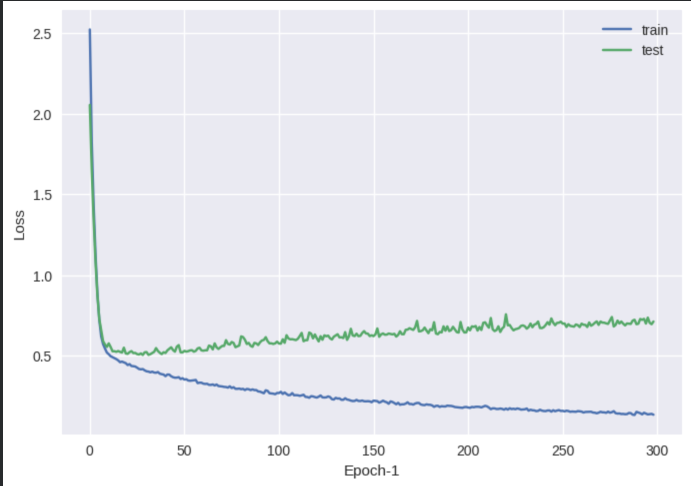

Figure 3. Archived comparison. Adam, widths 64, 32, 16, batch 32, 300 epochs.

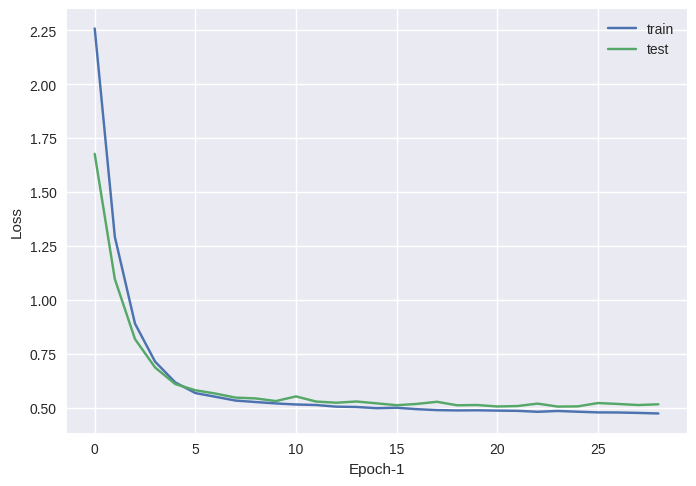

Figure 4. Archived comparison. Adam, width 20, batch 5, 30 epochs.

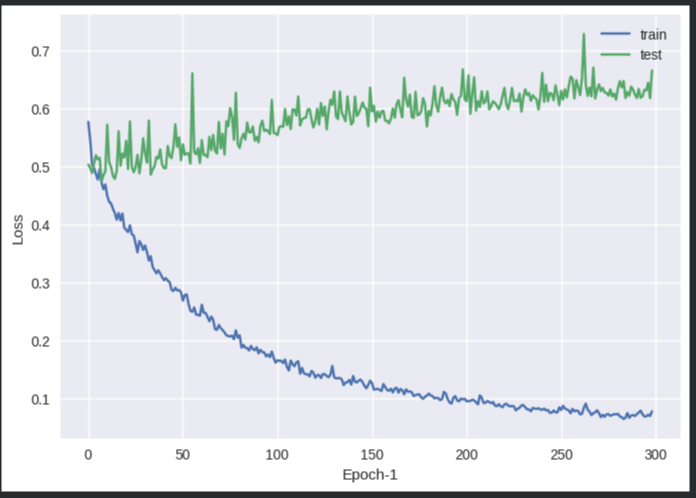

Figure 5. Archived comparison. Momentum SGD, widths 64, 32, 16, batch 32, 300 epochs.

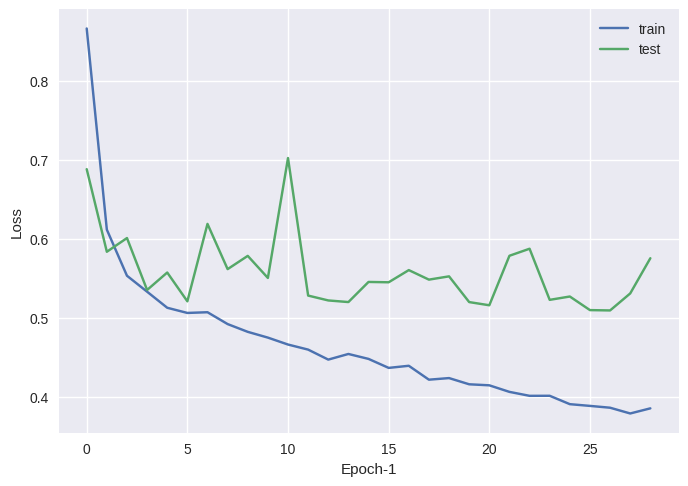

Figure 6. Archived comparison. Adam, widths 64, 32, 16, batch 5, 30 epochs.

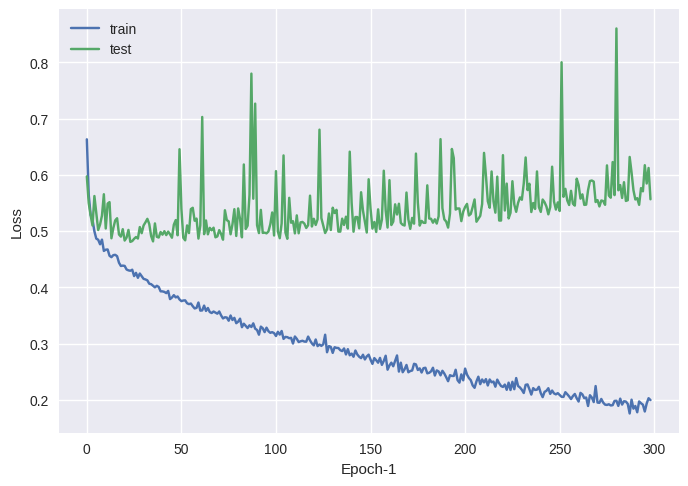

Figure 7. Archived comparison. Plain SGD, widths 64, 32, 16, batch 32, 300 epochs.

## Reproducible code
Use validation correlation to select an architecture. The test metrics for that selection are printed after training. The other test results describe each configuration and are not used to select it.

In [ ]:
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
from tensorflow import keras

path = Path('winequality-white.csv')
if not path.exists():
    urlretrieve(
        'https://archive.ics.uci.edu/ml/machine-learning-databases/'
        'wine-quality/winequality-white.csv',
        path,
    )
data = np.genfromtxt(path, delimiter=';', skip_header=1)
np.random.default_rng(1234).shuffle(data)
train, validation, test = data[:2550], data[2550:3000], data[3000:]
mean = train[:, :11].mean(axis=0)
std = train[:, :11].std(axis=0)

def split(rows):
    return ((rows[:, :11] - mean) / std).astype('float32'), rows[:, 11]

x_train, y_train = split(train)
x_val, y_val = split(validation)
x_test, y_test = split(test)

def build_model(widths, optimizer):
    keras.utils.set_random_seed(630)
    model = keras.Sequential(
        [keras.Input(shape=(11,))]
        + [keras.layers.Dense(width, activation='relu') for width in widths]
        + [keras.layers.Dense(1)]
    )
    model.compile(optimizer=optimizer, loss='mse', steps_per_execution=32)
    return model

configs = [
    ('SGD', (20,), 'sgd', 1),
    ('Momentum SGD', (20,), 'momentum', 1),
    ('Adam', (20,), 'adam', 1),
    ('Adam, deeper', (64, 32, 16), 'adam', 1),
    ('Adam, deeper, batch 5', (64, 32, 16), 'adam', 5),
    ('Adam, compact, batch 5', (32, 16, 8), 'adam', 5),
]
optimizers = {
    'sgd': lambda: keras.optimizers.SGD(learning_rate=0.01),
    'momentum': lambda: keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    'adam': lambda: keras.optimizers.Adam(learning_rate=0.001),
}
runs = {}
for label, widths, optimizer, batch in configs:
    model = build_model(widths, optimizers[optimizer]())
    history = model.fit(
        x_train, y_train, validation_data=(x_val, y_val),
        epochs=30, batch_size=batch, verbose=0,
    ).history
    val_prediction = model.predict(x_val, verbose=0).ravel()
    val_r = np.corrcoef(val_prediction, y_val)[0, 1]
    runs[label] = (model, history, val_r)

winner = max(runs, key=lambda label: runs[label][2])
print(f'Selected by validation correlation: {winner}')
print(f"{'Model':30} {'Val r':>8} {'Test MSE':>10} {'Test r':>8}")
for label, (model, _, val_r) in runs.items():
    prediction = model.predict(x_test, verbose=0).ravel()
    test_mse = np.mean((prediction - y_test)**2)
    test_r = np.corrcoef(prediction, y_test)[0, 1]
    print(f'{label:30} {val_r:8.4f} {test_mse:10.4f} {test_r:8.4f}')


In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(10, 9), sharex=True)
for ax, (label, (_, history, _)) in zip(axes.flat, runs.items()):
    epochs = np.arange(1, len(history['loss']) + 1)
    ax.semilogy(epochs, history['loss'], label='Train')
    ax.semilogy(epochs, history['val_loss'], label='Validation')
    ax.set(title=label, xlabel='Epoch', ylabel='MSE')
    ax.legend()
fig.tight_layout()
plt.show()

selected_model = runs[winner][0]
prediction = selected_model.predict(x_test, verbose=0).ravel()
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_test, prediction, s=12, alpha=0.25)
lo = min(y_test.min(), prediction.min())
hi = max(y_test.max(), prediction.max())
ax.plot([lo, hi], [lo, hi], 'k--', label='Exact prediction')
ax.set(xlabel='Observed quality', ylabel='Predicted quality', title=winner)
ax.legend()
plt.show()


## Code that generated the saved Adam run
The archived cells below document the exact configuration and plotting commands for the saved deep Adam run. The source file contains screenshots and settings for the other archived variants.